# Fullpage v4: training dengan tambahan target process

Notebook ini membaca data train v3 dan v4, profil GPU, metrik training, dan laporan generation development. Sel-selnya tidak mengulang training atau evaluasi dan tidak membuka benchmark final.

Contoh train bersifat sintetis dan belum ditinjau manusia. Target eksperimen adalah sedikitnya 76 dari 80 halaman valid.

## Alur eksperimen

1. Menyalin v3 sebagai dasar v4 dan menambahkan 960 target section role process hanya dari keluarga train.
2. Mempertahankan file validation dan test serta prompt, renderer, validator, sampler, dan budget output.
3. Membekukan konfigurasi 2048 token, probabilitas batch plan 0.7, microbatch 8, akumulasi 6, dan output section 1536 token.
4. Melatih dari INIT-2048-001 sampai update 1.800 sebagai TRAIN-022. Resume persis sampai update 3.600 sebagai TRAIN-024.
5. Membandingkan dua snapshot pada 80 permintaan development yang sama. TRAIN-023 berhenti pada preflight penyimpanan di update 0 dan tidak memperbarui bobot.

In [1]:
import json
from collections import Counter
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
def read_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))

selection = read_json(ROOT / 'reports/training/FULLPAGE-V4_DEVELOPMENT_SELECTION.json')
print('Project root:', ROOT)
print('Final benchmark opened:', selection['final_opened'])
print('Development requests:', selection['development_total'])

Project root: F:\Generative_AI\Vibe_Coding_Proyek_1
Final benchmark opened: False
Development requests: 80


## Perubahan dan validasi dataset

In [2]:
v3_manifest = read_json(ROOT / 'data/processed/fullpage/v3/manifest.json')
v4_manifest = read_json(ROOT / 'data/processed/fullpage/v4/manifest.json')
change = selection['data_change']
heldout = ('validation.jsonl', 'validation.requests.jsonl', 'test.jsonl', 'test.requests.jsonl')
heldout_unchanged = {name: v3_manifest['files'][name]['sha256'] == v4_manifest['files'][name]['sha256'] for name in heldout}
assert all(heldout_unchanged.values())
display(pd.DataFrame([
    {'item': 'baris train v3', 'nilai': change['train_rows_v3']},
    {'item': 'baris train v4', 'nilai': change['train_rows_v4']},
    {'item': 'target train baru', 'nilai': change['added_rows']},
    {'item': 'section process di v3', 'nilai': change['section_process_rows_v3']},
    {'item': 'section process di v4', 'nilai': change['section_process_rows_v4']},
    {'item': 'contoh ditinjau manusia', 'nilai': v4_manifest['human_reviewed']},
    {'item': 'semua file heldout tidak berubah', 'nilai': all(heldout_unchanged.values())},
]))

,item,nilai
0,baris train v3,23040
1,baris train v4,24000
2,target train baru,960
3,section process di v3,480
4,section process di v4,1440
5,contoh ditinjau manusia,False
6,semua file heldout tidak berubah,True


,v3,v4
hero,5280,5280
footer,3360,3360
about,2400,2400
services,1440,1440
process,480,1440
navigation,1440,1440
faq,720,720
portfolio,720,720
benefits,480,480
contact,480,480


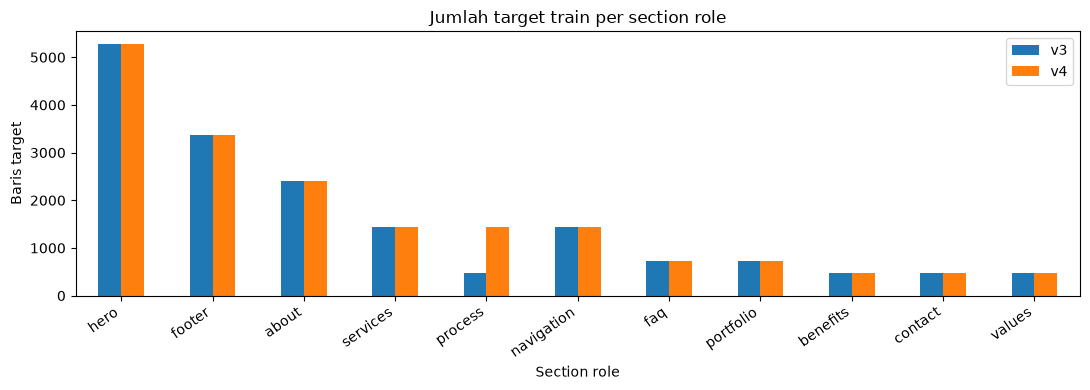

In [3]:
role_frame = pd.DataFrame({
    'v3': change['section_role_rows_v3'],
    'v4': change['section_role_rows_v4'],
}).fillna(0).astype(int).sort_values('v4', ascending=False)
display(role_frame)
ax = role_frame.plot(kind='bar', figsize=(11, 4), title='Jumlah target train per section role')
ax.set_ylabel('Baris target')
ax.set_xlabel('Section role')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

## Profil dan konfigurasi GPU

Sweep mengukur throughput, memori, dan stabilitas pada RTX 5070. Batch 16 menjadi yang tercepat, sekitar 2.6 persen di atas batch 8. Eksperimen tetap memakai batch 8 dan akumulasi 6 agar setting yang disepakati tidak berubah di tengah eksperimen.

,batch,accumulation,tokens/sec,VRAM peak GiB
0,4,12,49414,1.26
1,8,6,51562,2.13
2,12,4,52848,3.00
3,16,3,52889,3.90


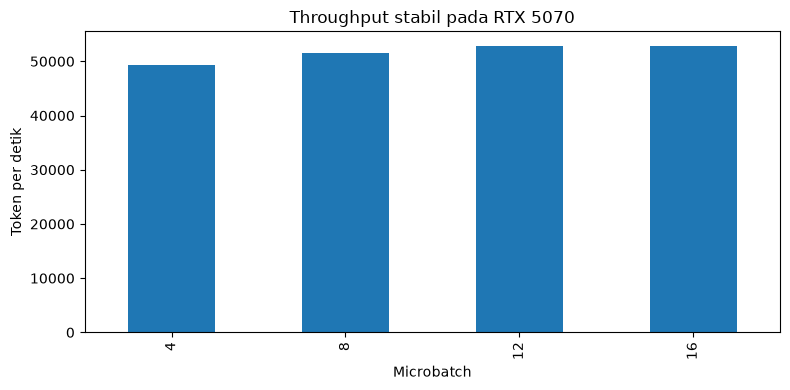

,parameter,value
0,batch_size,8
1,gradient_accumulation,6
2,max_steps,3600
3,plan_batch_probability,0.7
4,warmup_steps,180
5,validation_interval,600
6,checkpoint_interval,600
7,precision,bf16
8,device,cuda


In [4]:
profile = read_json(ROOT / 'reports/training/FULLPAGE-GPU-005.json')
profile_rows = [row for row in profile['results'] if row.get('status') == 'stable']
profile_frame = pd.DataFrame([{
    'batch': row['batch'], 'accumulation': row['accumulation'],
    'tokens/sec': round(row['tokens_per_second']),
    'VRAM peak GiB': round(row['peak_reserved_bytes'] / 2**30, 2),
} for row in profile_rows])
display(profile_frame)
ax = profile_frame.plot(x='batch', y='tokens/sec', kind='bar', legend=False, figsize=(8, 4), title='Throughput stabil pada RTX 5070')
ax.set_ylabel('Token per detik')
ax.set_xlabel('Microbatch')
plt.tight_layout()
plt.show()
config = read_json(ROOT / 'configs/fullpage/training-improvement-v4.json')
display(pd.DataFrame([{'parameter': key, 'value': config.get(key)} for key in ('batch_size', 'gradient_accumulation', 'max_steps', 'plan_batch_probability', 'warmup_steps', 'validation_interval', 'checkpoint_interval', 'precision', 'device')]))

## Training dan validasi cross-entropy

,run_id,step,loss,perplexity,valid_tokens
0,TRAIN-022,0,6.266233,526.490117,238822
601,TRAIN-022,600,0.121490,1.129178,238822
1202,TRAIN-022,1200,0.009746,1.009794,238822
1803,TRAIN-022,1800,0.006403,1.006424,238822
1804,TRAIN-024,1800,0.006403,1.006424,238822
2405,TRAIN-024,2400,0.006491,1.006512,238822
3006,TRAIN-024,3000,0.007504,1.007532,238822
3607,TRAIN-024,3600,0.007639,1.007668,238822


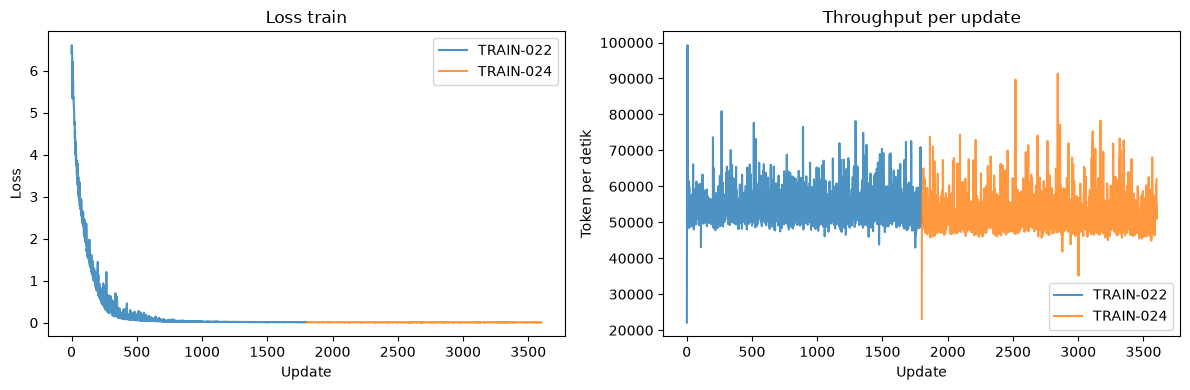

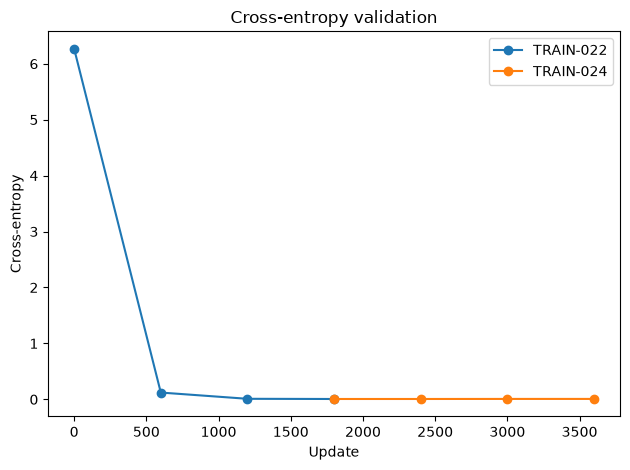

In [5]:
metric_rows = []
for run_id in ('TRAIN-022', 'TRAIN-024'):
    with (ROOT / f'outputs/metrics/{run_id}.jsonl').open(encoding='utf-8') as handle:
        metric_rows.extend({'run_id': run_id, **json.loads(line)} for line in handle if line.strip())
metrics = pd.DataFrame(metric_rows)
train = metrics[metrics['event'] == 'train'].copy()
validation = metrics[metrics['event'] == 'validation'].copy()
display(validation[['run_id', 'step', 'loss', 'perplexity', 'valid_tokens']])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for run_id, rows in train.groupby('run_id'):
    axes[0].plot(rows['step'], rows['loss'], label=run_id, alpha=.8)
    axes[1].plot(rows['step'], rows['tokens_per_second'], label=run_id, alpha=.8)
axes[0].set_title('Loss train')
axes[0].set_xlabel('Update')
axes[0].set_ylabel('Loss')
axes[1].set_title('Throughput per update')
axes[1].set_xlabel('Update')
axes[1].set_ylabel('Token per detik')
for axis in axes: axis.legend()
plt.tight_layout()
plt.show()
for run_id, rows in validation.groupby('run_id'):
    plt.plot(rows['step'], rows['loss'], marker='o', label=run_id)
plt.title('Cross-entropy validation')
plt.xlabel('Update')
plt.ylabel('Cross-entropy')
plt.legend()
plt.tight_layout()
plt.show()

## Hasil generation development

,run,update,complete,total,CE,role,rate
0,TRAIN-019,3600,70,80,0.007519,historical reference,0.875
1,TRAIN-022,1800,64,80,0.006403,v4 candidate,0.800
2,TRAIN-024,3600,68,80,0.007639,v4 candidate,0.850


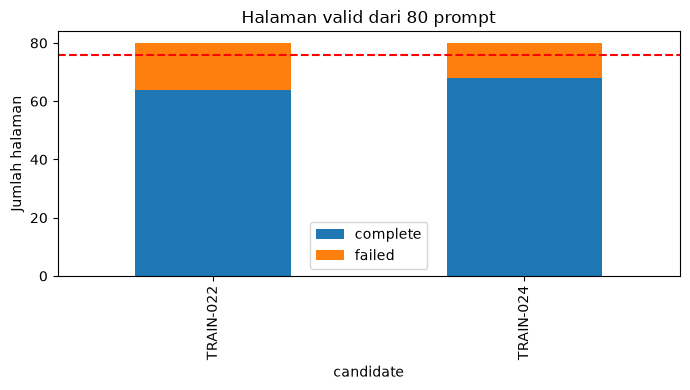

Best observed: TRAIN-024
Promotable: None
Target met: False


In [6]:
rows = [{
    'run': selection['historical_baseline']['run_id'],
    'update': selection['historical_baseline']['step'],
    'complete': selection['historical_baseline']['complete'],
    'total': selection['historical_baseline']['total'],
    'CE': selection['historical_baseline']['development_ce'],
    'role': 'historical reference',
}] + [{
    'run': item['run_id'], 'update': item['step'],
    'complete': item['development_complete'], 'total': item['development_total'],
    'CE': item['development_ce'], 'role': 'v4 candidate',
} for item in selection['candidates']]
results = pd.DataFrame(rows)
results['rate'] = results['complete'] / results['total']
display(results)
candidates = pd.DataFrame([{
    'candidate': item['run_id'], 'step': item['step'],
    'complete': item['development_complete'], 'failed': item['development_total'] - item['development_complete'],
} for item in selection['candidates']])
ax = candidates.set_index('candidate')[['complete', 'failed']].plot(kind='bar', stacked=True, figsize=(7, 4), title='Halaman valid dari 80 prompt')
ax.axhline(selection['target']['minimum_complete_pages'], color='red', linestyle='--', label='Ambang 76')
ax.set_ylabel('Jumlah halaman')
plt.tight_layout()
plt.show()
print('Best observed:', selection['best_observed_by_complete_pages_then_ce'])
print('Promotable:', selection['promotable_candidate'])
print('Target met:', selection['model_gate_passed'])

## Rincian kelompok prompt dan pola error

In [7]:
group_rows = []
for item in selection['candidates']:
    for group, stats in item['groups'].items():
        group_rows.append({'run': item['run_id'], 'group': group.replace('_', ' '), **stats})
group_frame = pd.DataFrame(group_rows)
display(group_frame)
errors = []
for item in selection['candidates']:
    for error in item['top_generation_errors'][:6]:
        errors.append({'run': item['run_id'], 'task': error['task'], 'stage': error['stage'], 'attempts': error['attempts'], 'pages': error['affected_pages'], 'error': error['error']})
display(pd.DataFrame(errors))

,run,group,total,complete,first_attempt
0,TRAIN-022,landing page:plain css,20,18,17
1,TRAIN-022,landing page:tailwind,20,18,17
2,TRAIN-022,company profile:plain css,20,14,14
3,TRAIN-022,company profile:tailwind,20,14,14
4,TRAIN-024,landing page:plain css,20,19,19
5,TRAIN-024,landing page:tailwind,20,19,19
6,TRAIN-024,company profile:plain css,20,15,15
7,TRAIN-024,company profile:tailwind,20,15,15


,run,task,stage,attempts,pages,error
0,TRAIN-022,page_plan,plan,13,7,Plan request identity/style mismatch
1,TRAIN-022,section_content,about,6,4,Required fact text mismatch: about
2,TRAIN-022,section_content,about,4,2,"section:[]: {'id': 'about', 'props': {'heading..."
3,TRAIN-022,section_content,main,4,2,Hero brand fact mismatch
4,TRAIN-022,section_content,nav,4,2,Brand fact mismatch
5,TRAIN-022,section_content,about,2,2,"section:[]: {'id': 'about', 'props': {'heading..."
6,TRAIN-024,page_plan,plan,16,9,Plan request identity/style mismatch
7,TRAIN-024,section_content,main,4,2,Hero brand fact mismatch
8,TRAIN-024,section_content,nav,4,2,Brand fact mismatch
9,TRAIN-024,section_content,about,2,1,Required fact text mismatch: about


## Kesimpulan dan batas hasil

Update 3.600 mendapat hasil tertinggi pada dua kandidat v4, yaitu 68/80 atau 85 persen. Update 1.800 mendapat 64/80 atau 80 persen. Perbaikan empat halaman terlihat pada suite development yang sama, tetapi target 76/80 belum tercapai dan belum ada candidate yang lolos gate.

Kegagalan yang tersisa mencakup ketidakcocokan identitas atau gaya pada rancangan, fakta merek pada bagian halaman, dan beberapa ketidakcocokan teks fakta. Pola ini menunjukkan pekerjaan lanjutan perlu menangani konsistensi perencanaan dan fakta. Perubahan data ini belum membuktikan sebab-akibat karena belum ada eksperimen terkontrol dengan beberapa seed.

TRAIN-019 dengan 70/80 ditampilkan sebagai referensi historis, bukan sebagai kandidat v4. Data train sintetis belum ditinjau manusia. Tidak ada evaluasi visual di browser dan benchmark final tetap tertutup.

## Bukti run

Training utama: RUN-353 untuk update 1.800 dan RUN-367 untuk resume sampai 3.600. Evaluasi: RUN-355 dan RUN-369. Pemilihan: RUN-374. Preflight penyimpanan yang gagal sebelum weight update tercatat pada RUN-357. Pemulihan checkpoint dengan checksum dan tautan diperiksa pada RUN-361 dan RUN-365, lalu resume diverifikasi pada RUN-366. Semua eksekusi dan retry dicatat pada logs/LOG_EKSPERIMEN_DAN_INTERAKSI_LLM.md dan logs/RUN-*.txt. Laporan pemilihan ada di reports/training/FULLPAGE-V4_DEVELOPMENT_SELECTION.json.